# Faba bean PEAMUST collection structure based on phenotypic data

## Summary 

Analysis of the structure of the PEAMUST Vicia faba INRAE collection based on phenotypic traits. 

Most phenotypic data (flower color, etc.) were recoded as 0 (absence of color), 1 (color #1), etc. as **nominal data** (Nominal data consists of categories without a meaningful order). 

Only **height** and SumTem are continuous variables. 

## Traits measured

**Flowering start date**: calendar date.   
**SumTem (Semis-DFLO) (base 0)**: ?  

**Flower color:**  
  - Banner ("étendard") color: 0 (NA), 1 (white), to 9 or 10 (mixed).  
  - Stripe color intensity on the banner: from 0 (absence) to 9 (intense).  
  - Wing petal color intensity: 1 (white), 2 (uniform color) or 3 (spotted).  
  - Spot color: 0 (absence), 1 (white), 2 (violet), 3 (dark brown), 4 (pale brown), 5 (pink), 6 (red), 7 (yellow), 8 (other color) or 9 (mixed  ).  
 
**Growth**
  - Growth type: i (indeterminate), i/2 (semi-determinate), ti (terminal inflorescence).  
  - Height at flowering onset: in centimeters.   

**Seed traits**  
- Seed color: 0 (absence), 1 (black), 2 (brown), 3 (beige), 4 (green), 5 (red), 6 (purple), 7 (yellow), 8 (cream), 9 (grey), 10 (pink) or 11 (mixed).  
- Seed ornementation spot: 0 (absence), 1 (concentric), 2 (stained), 3 (marbled), 5 (speckled), 6 (spotted), 7 (mottled) or 8 (mixed).     
- Seed ornementation color: 0 (absence), 1 (black), 2 (brown), 3 (beige), 4 (green), 5 (red), 6 (purple), 7 (yellow), 8 (cream), 9 (grey), 10 (pink) or 11 (mixed).
- Hilum color: 1 (colorless), 2 (black), 3 (grey).  
- Seed size (Thousand Seed Weight): 1 (< 300 g), 2 (< 500 g), 3 (< 750 g), 4 (> 750 g).

## Python libraries


In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

from prince import FAMD # installed using pip install prince

In [130]:
# Import dataset
pheno_df = pd.read_csv("../../../01.data/2012_flower_and_seed_phenotypes/flower_and_seed_phenotypes.csv", sep=",")
print(pheno_df.shape)
pheno_df.head()

(248, 15)


,ivip,sowing_date,flowering_start_date,sum_tem,banner_color,banner_stripe_color_intensity,wing_petal_color,spot_color,growth_type,height_at_flowering,seed_color,seed_ornementation_spot,seed_ornementation_color,hilum_color,thousand_seed_weight
0,IVIP100034,12/3/12,5/29/12,939.10,1.0,3.0,3.0,3.0,i,55.0,1,3,2,2.0,1
1,IVIP100081,12/3/12,5/28/12,920.05,1.0,3.0,3.0,3.0,i,150.0,3,0,0,2.0,3
2,IVIP100120,12/3/12,5/31/12,978.30,1.0,2.0,3.0,3.0,i,155.0,3,0,0,2.0,3
3,IVIP100121,12/3/12,5/27/12,902.35,1.0,3.0,3.0,9.0,i,180.0,3,0,0,NaN,3
4,IVIP100123,12/3/12,5/19/12,764.60,1.0,2.0,3.0,3.0,i,135.0,3,0,0,NaN,2


## Data description

In [131]:
# Create a plot using seaborn to vizualize the distributions of nominal variables in a dataframe

# Plot a grid of variable distributions
def plot_nominal_distributions(df, width=10, height=6):
    # Determine the number of columns for the grid
    num_cols = 2  # You can adjust this based on your preference
    num_rows = (len(df.columns) + num_cols - 1) // num_cols  # Ceiling division

    # Create a figure and axes
    plt.figure(figsize=(width, height))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 5 * num_rows))
    axes = axes.flatten()

    # Plot each variable distribution
    for i, column in enumerate(df.columns):
        sns.countplot(data=df, x=column, ax=axes[i])
        axes[i].set_title(f'Distribution of {column}')
        axes[i].set_xlabel(column)
        axes[i].set_ylabel('Count')

    # Hide any empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()







In [132]:
pheno_df.head()

,ivip,sowing_date,flowering_start_date,sum_tem,banner_color,banner_stripe_color_intensity,wing_petal_color,spot_color,growth_type,height_at_flowering,seed_color,seed_ornementation_spot,seed_ornementation_color,hilum_color,thousand_seed_weight
0,IVIP100034,12/3/12,5/29/12,939.10,1.0,3.0,3.0,3.0,i,55.0,1,3,2,2.0,1
1,IVIP100081,12/3/12,5/28/12,920.05,1.0,3.0,3.0,3.0,i,150.0,3,0,0,2.0,3
2,IVIP100120,12/3/12,5/31/12,978.30,1.0,2.0,3.0,3.0,i,155.0,3,0,0,2.0,3
3,IVIP100121,12/3/12,5/27/12,902.35,1.0,3.0,3.0,9.0,i,180.0,3,0,0,NaN,3
4,IVIP100123,12/3/12,5/19/12,764.60,1.0,2.0,3.0,3.0,i,135.0,3,0,0,NaN,2


<Figure size 800x600 with 0 Axes>

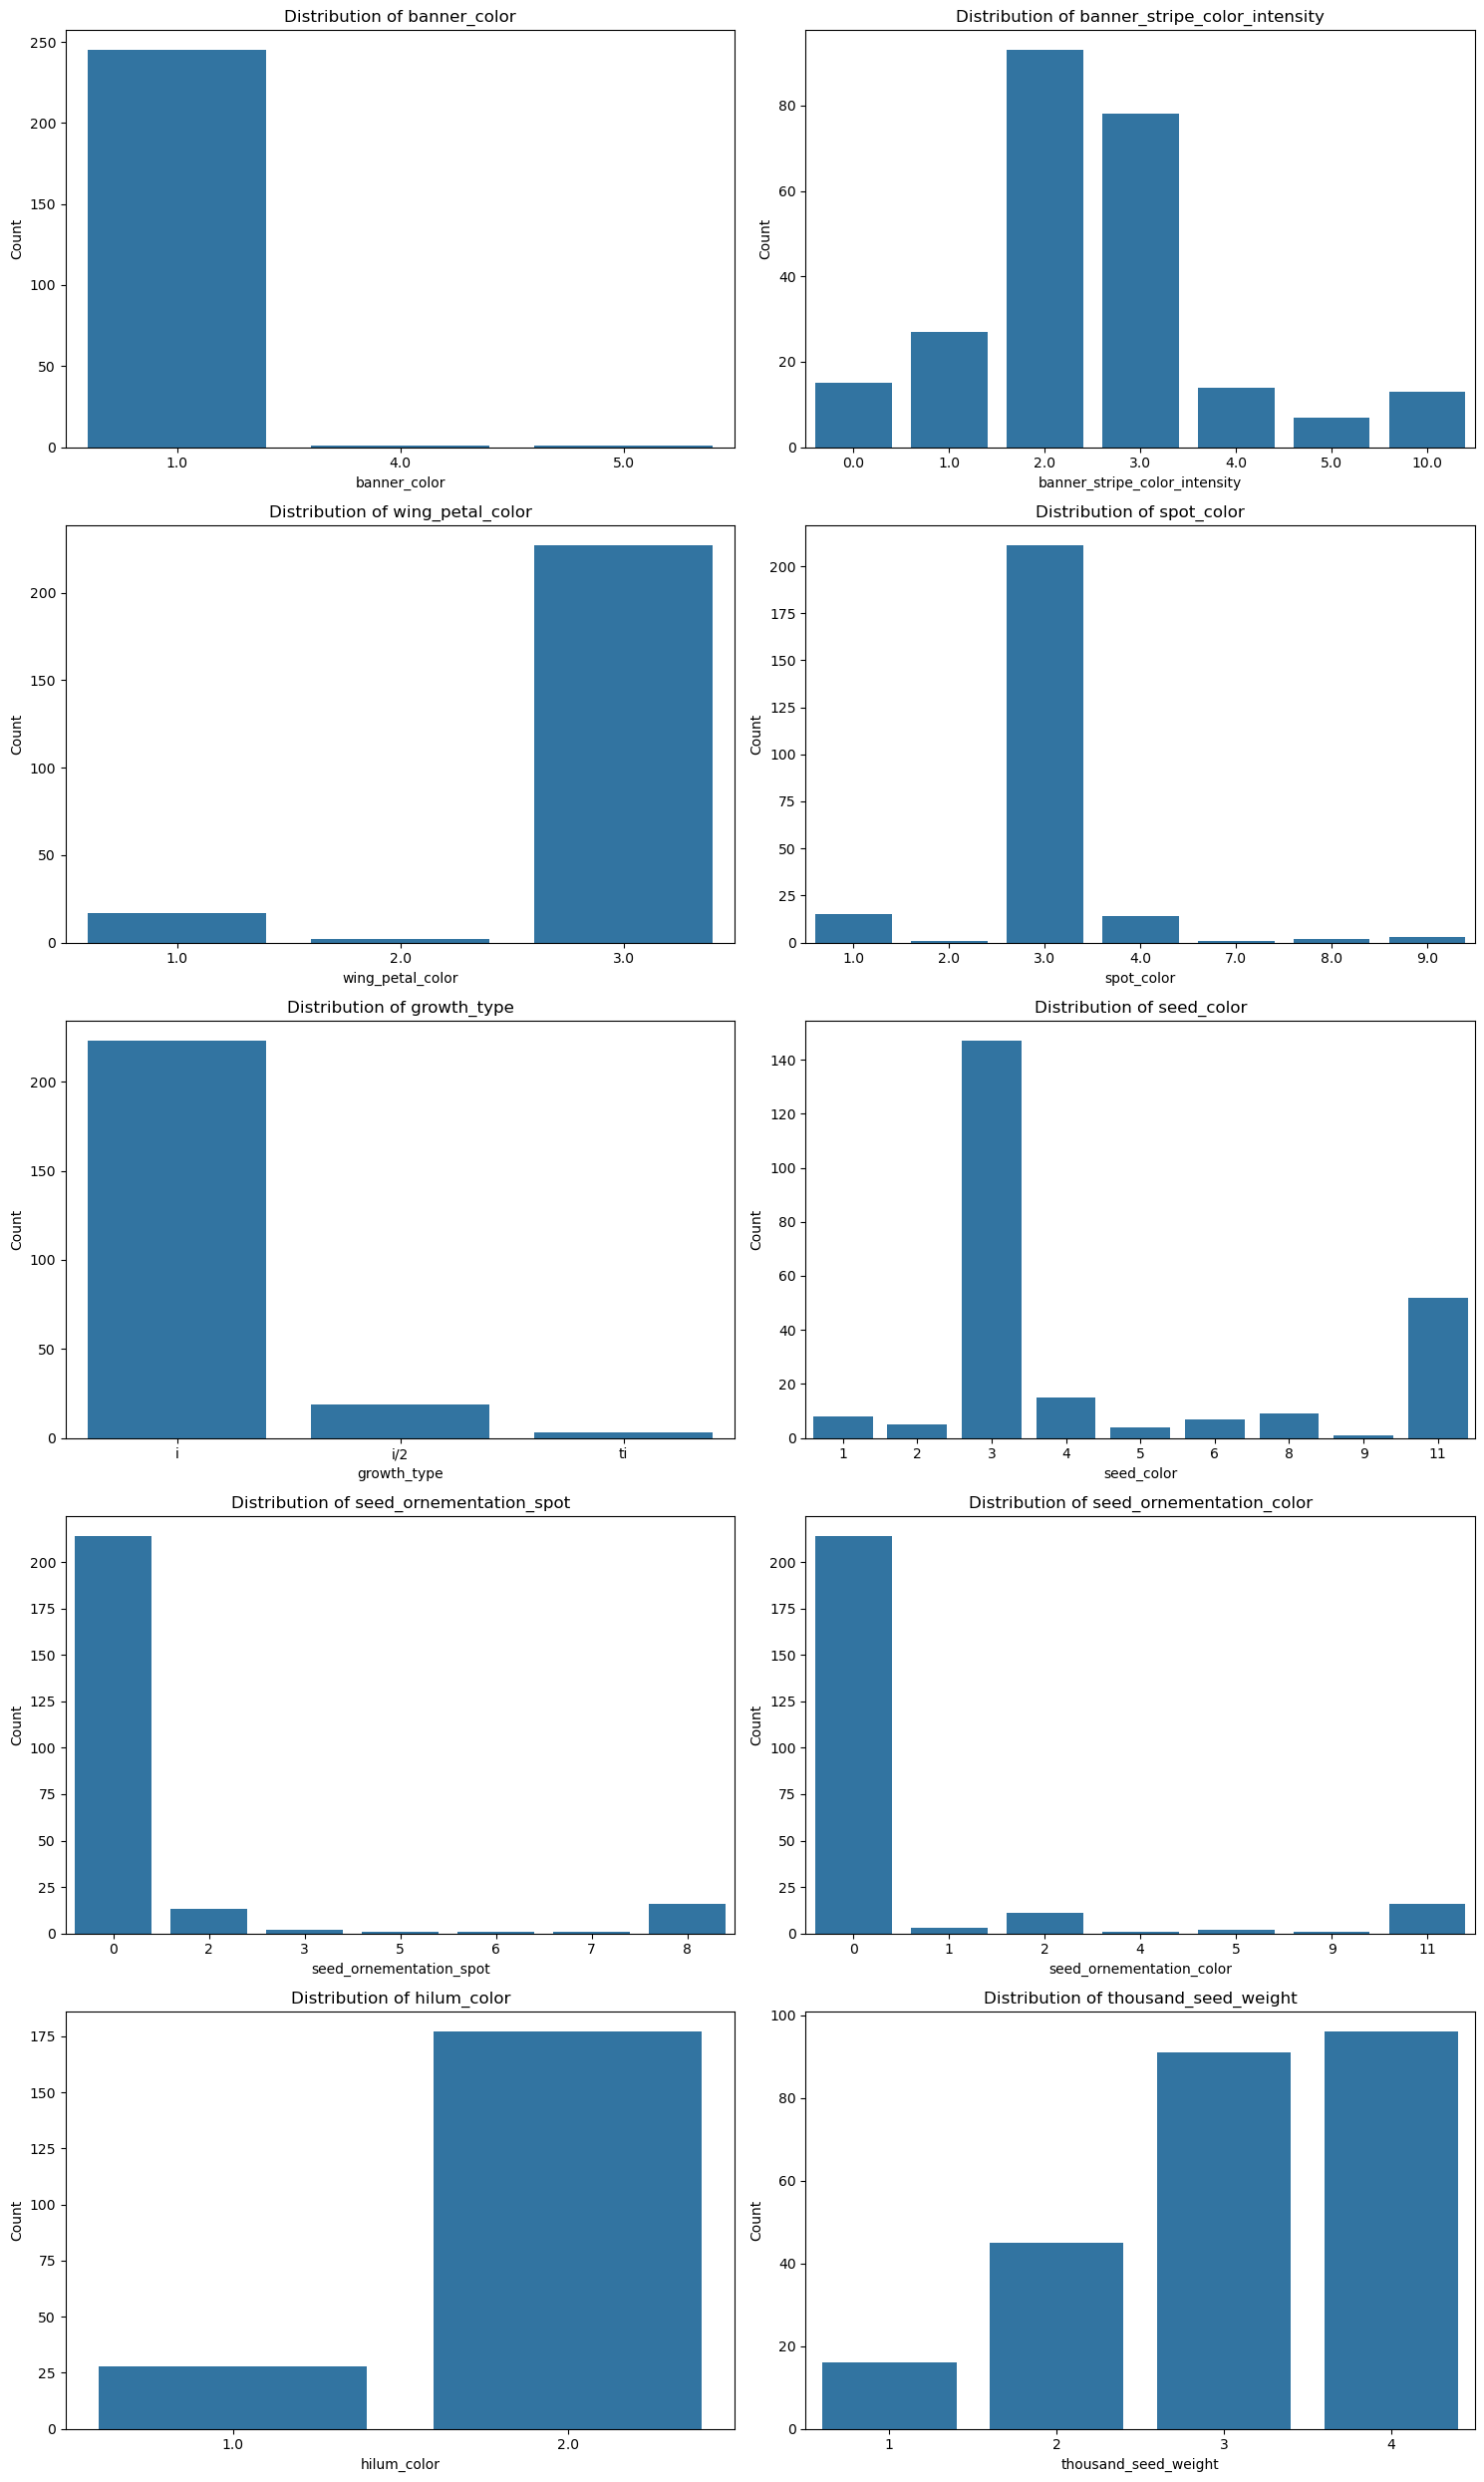

In [133]:
# Columns with nominal variables
continuous_columns = ['sum_tem', 'height_at_flowering']
ivip_date_columns = ['ivip', 'sowing_date', 'flowering_start_date']
cols_to_drop = ivip_date_columns + continuous_columns

# Plot the distributions of nominal and quantitative variables
pheno_df_reduced = pheno_df.drop(cols_to_drop, axis=1)

plot_nominal_distributions(pheno_df_reduced, width=8, height=6)

# PCA analysis and comparison with genetic structure

## One-hot encoding of nominal data

In [134]:
# Step 1: One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)  # sparse=False to get a dense array
one_hot_encoded_data = encoder.fit_transform(pheno_df_reduced)


## PCA dimension reduction and plot

In [135]:
pca = PCA(n_components=2)  # Reduce to 2 dimensions for visualization
reduced_data = pca.fit_transform(one_hot_encoded_data)

## Import genetic structure information and add to PCA results

In [136]:
genetic_clusters = pd.read_csv("../../../00.info/02.genetic_structure_jonathan_dijon/faba_bean_ivip_and_genetic_cluster.csv", sep=",")
cols2keep =['ivip', 'cluster_dapc', 'cluster_name']
genetic_clusters_reduced = genetic_clusters[cols2keep]

In [137]:
reduced_data_df = pd.DataFrame(reduced_data, columns=['PC1', 'PC2'])
# Add ivip column from the phenotypic dataframe
reduced_data_df['ivip'] = pheno_df['ivip'].values

# Merge with genetic clusters
reduced_data_df = reduced_data_df.merge(genetic_clusters_reduced, on='ivip', how='inner')

<Axes: xlabel='PC1', ylabel='PC2'>

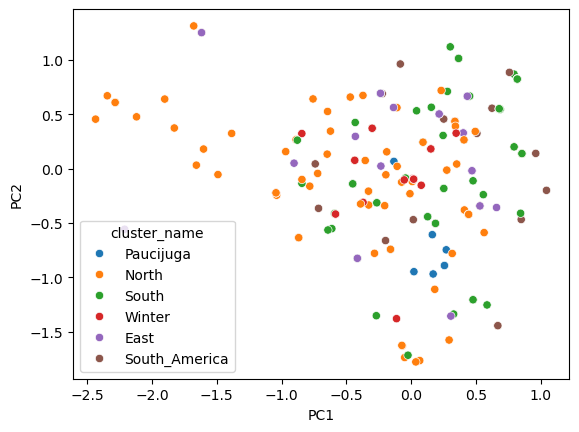

In [138]:
# Create a scatter plot with seaborn
sns.scatterplot(data=reduced_data_df, x='PC1', y='PC2', hue='cluster_name')

# Factor analysis of mixed data (FAMD)

This analysis can combine categorical nominal data with quantitative data.  

The term mixed refers to the use of both quantitative and qualitative variables. Roughly, we can say that FAMD works as a principal components analysis (PCA) for quantitative variables and as a multiple correspondence analysis (MCA) for qualitative variables.

Source: https://www.wikiwand.com/en/articles/Factor_analysis_of_mixed_data 

Code is mostly based on: https://maxhalford.github.io/prince/famd/ 

## Scaling of quantitative variables

In [139]:
quantitative_variables = ['sum_tem', 'height_at_flowering']
qualitative_variables = ['banner_color', 'banner_stripe_color_intensity', 'wing_petal_color','spot_color','growth_type','seed_color','seed_ornementation_spot','seed_ornementation_color','hilum_color','thousand_seed_weight']

Based on Pagès et al, quantitative data must be scaled (centered, reduced).

In [140]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pheno_df[quantitative_variables])

In [141]:
pheno_df_quali = pheno_df[qualitative_variables]

Combined scaled quantitative data with qualitative data. 

In [142]:
# Combined scaled quantitative dataframe with qualitative dataframe
quali_quanti_df = pd.concat([pd.DataFrame(scaled_data, columns=quantitative_variables), pheno_df_quali], axis=1)

# Impute missing values
imputer = SimpleImputer(strategy='most_frequent')
quali_quanti_imputed = imputer.fit_transform(quali_quanti_df)
quali_quanti_imputed_df = pd.DataFrame(quali_quanti_imputed, columns=quantitative_variables + qualitative_variables)


# Convert quantitative variables to float
quali_quanti_imputed_df[quantitative_variables] = quali_quanti_imputed_df[quantitative_variables].astype(float)



In [143]:
famd = FAMD(n_components=2, 
            n_iter=3, 
            random_state=42, 
            engine="sklearn", 
            handle_unknown="error")  # same parameter as sklearn.preprocessing.OneHotEncoder


famd = famd.fit(quali_quanti_imputed_df)

famd.eigenvalues_summary['% of variance']

component
0    9.69%
1    7.08%
Name: % of variance, dtype: object

In [144]:
f1_variance = famd.eigenvalues_summary['% of variance'][0]
f2_variance = famd.eigenvalues_summary['% of variance'][1]

## Plot

In [145]:
# Add genetic group name to the famd dataframe
famd_df = famd.row_coordinates(quali_quanti_imputed_df)
famd_df['ivip'] = pheno_df['ivip'].values
famd_df = famd_df.merge(genetic_clusters_reduced, on='ivip', how='inner')

In [146]:
famd_df_renamed = famd_df.rename(columns={0: 'F1', 1: 'F2'})
famd_df_renamed

,F1,F2,ivip,cluster_dapc,cluster_name
0,-4.282009,-8.910804,IVIP100034,1.0,Paucijuga
1,-1.070343,-0.064583,IVIP100081,4.0,North
2,-1.044318,-0.030741,IVIP100120,4.0,North
3,-1.001217,0.410466,IVIP100121,4.0,North
4,-1.154414,-0.209713,IVIP100123,4.0,North
...,...,...,...,...,...
243,-1.375078,0.197279,IVIP103288,3.0,South
244,-1.409521,0.161983,IVIP103295,3.0,South
245,-1.409275,0.159510,IVIP103304,3.0,South
246,-1.079917,-0.072314,IVIP103312,2.0,Winter


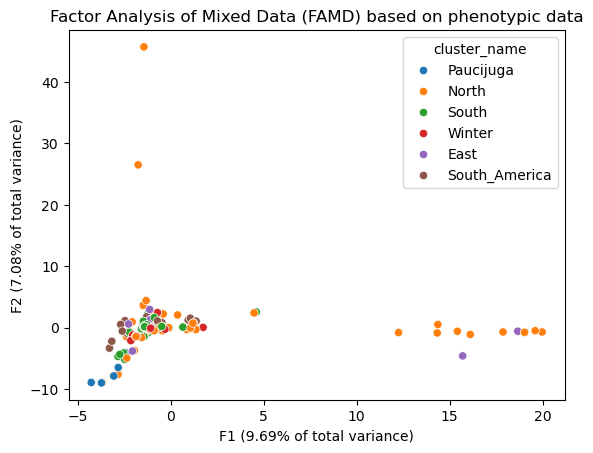

In [147]:
# Plot using seaborn
ax = sns.scatterplot(data=famd_df_renamed, x='F1', y='F2', hue='cluster_name')

# Add variance explained for axis 1
xlabel = 'F1' + ' (' + str(f1_variance) + ' of total variance)'
ylabel = 'F2' + ' (' + str(f2_variance) + ' of total variance)'

ax.set_xlabel(xlabel)
ax.set_ylabel(ylabel)

plt.title("Factor Analysis of Mixed Data (FAMD) based on phenotypic data")

# Save plot
plt.savefig("./famd_phenotypic_data.png")
plt.savefig("./famd_phenotypic_data.pdf")

plt.show()

# References

Pagès (2004) Analyse factorielle de données mixtes. _Revue de statistique appliquée_ 52(4):93-111